# BigMart Sales Prediction
Predict `Item_Outlet_Sales` for each product at each outlet.

**Pipeline:** setup -> data cleaning -> EDA -> feature engineering -> modelling -> evaluation (RMSE, R2, confusion matrix, precision, recall, F1) -> submission.

> The target is continuous, so the confusion matrix / precision / recall / F1 are computed after binning sales into **Low / Medium / High** classes (tertiles of the training sales). RMSE (the competition metric) is reported as well.

**Data:** put `train_v9rqX0R.csv` and `test_AbJTz2l.csv` in the `data/` folder next to this notebook.

In [2]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import train_test_split, KFold, cross_val_predict
from sklearn.metrics import (mean_squared_error, r2_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, precision_recall_fscore_support, accuracy_score)
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)

DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)   # creates the data folder if missing
TRAIN_PATH = os.path.join(DATA_DIR, "train_v9rqX0R.csv")
TEST_PATH = os.path.join(DATA_DIR, "test_AbJTz2l.csv")
for p in (TRAIN_PATH, TEST_PATH):
    assert os.path.exists(p), f"Missing {p} - copy the CSV into the data/ folder"
TARGET = "Item_Outlet_Sales"

## 1. Load data

In [3]:
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)
print("train:", train.shape, "| test:", test.shape)
train.head()

train: (8523, 12) | test: (5681, 11)


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


In [4]:
train.info()
train.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   str    
 1   Item_Weight                7060 non-null   float64
 2   Item_Fat_Content           8523 non-null   str    
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   str    
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   str    
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                6113 non-null   str    
 9   Outlet_Location_Type       8523 non-null   str    
 10  Outlet_Type                8523 non-null   str    
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), str(7)
memory usage: 799.2 KB


,count,mean,std,min,25%,50%,75%,max
Item_Weight,7060.0,12.857645,4.643456,4.555,8.773750,12.600000,16.850000,21.350000
Item_Visibility,8523.0,0.066132,0.051598,0.000,0.026989,0.053931,0.094585,0.328391
Item_MRP,8523.0,140.992782,62.275067,31.290,93.826500,143.012800,185.643700,266.888400
Outlet_Establishment_Year,8523.0,1997.831867,8.371760,1985.000,1987.000000,1999.000000,2004.000000,2009.000000
Item_Outlet_Sales,8523.0,2181.288914,1706.499616,33.290,834.247400,1794.331000,3101.296400,13086.964800


## 2. Data cleaning
### 2.1 Inspect problems

In [5]:
print("Missing values (train):\n", train.isnull().sum()[lambda s: s > 0], "\n")
print("Missing values (test):\n", test.isnull().sum()[lambda s: s > 0], "\n")
print("Fat content labels:", train["Item_Fat_Content"].unique())
print("Zero-visibility rows:", (train["Item_Visibility"] == 0).sum())
print("Duplicate rows:", train.duplicated().sum())

Missing values (train):
 Item_Weight    1463
Outlet_Size    2410
dtype: int64 

Missing values (test):
 Item_Weight     976
Outlet_Size    1606
dtype: int64 

Fat content labels: <StringArray>
['Low Fat', 'Regular', 'low fat', 'LF', 'reg']
Length: 5, dtype: str
Zero-visibility rows: 526
Duplicate rows: 0


### 2.2 Fix them
- Inconsistent fat labels (`LF`, `low fat`, `reg`) -> `Low Fat` / `Regular`; non-consumables (`NC*` ids) -> `Non-Edible`.
- `Item_Weight` missing -> same item's known weight in other outlets, else item-type median.
- `Outlet_Size` missing -> most common size for the outlet type.
- `Item_Visibility == 0` is impossible -> treated as missing, replaced by the item's mean visibility.

In [6]:
full = pd.concat([train.assign(is_train=1), test.assign(is_train=0)], ignore_index=True)

full["Item_Fat_Content"] = full["Item_Fat_Content"].replace({"LF": "Low Fat", "low fat": "Low Fat", "reg": "Regular"})
full["Item_Category"] = full["Item_Identifier"].str[:2].map({"FD": "Food", "DR": "Drinks", "NC": "Non-Consumable"})
full.loc[full["Item_Category"] == "Non-Consumable", "Item_Fat_Content"] = "Non-Edible"

full["Item_Weight"] = full["Item_Weight"].fillna(full.groupby("Item_Identifier")["Item_Weight"].transform("mean"))
full["Item_Weight"] = full["Item_Weight"].fillna(full.groupby("Item_Type")["Item_Weight"].transform("median"))

mode_size = full.groupby("Outlet_Type")["Outlet_Size"].agg(lambda s: s.mode().iloc[0] if not s.mode().empty else "Small")
full["Outlet_Size"] = full["Outlet_Size"].fillna(full["Outlet_Type"].map(mode_size))

vis = full["Item_Visibility"].replace(0, np.nan)
full["Item_Visibility"] = vis.fillna(vis.groupby(full["Item_Identifier"]).transform("mean")).fillna(vis.mean())

print(full.drop(columns=TARGET).isnull().sum().sum(), "missing values left (excluding target)")

0 missing values left (excluding target)


## 3. Exploratory data analysis

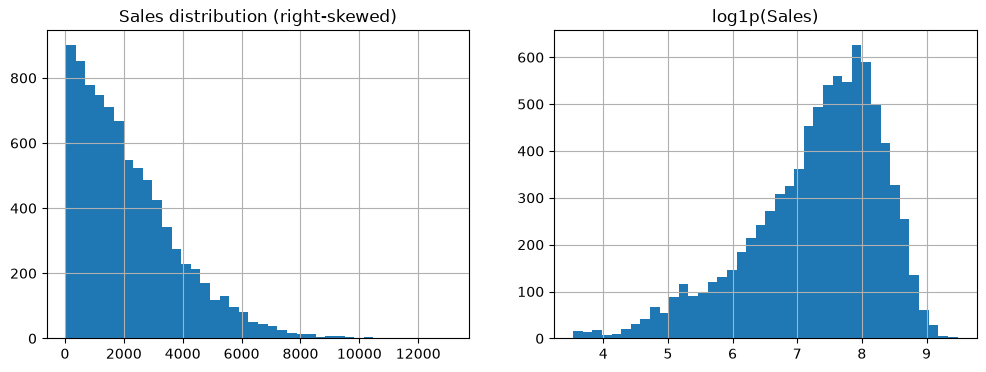

skew: 1.1775306028542798


In [7]:
tr = full[full.is_train == 1]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
tr[TARGET].hist(bins=40, ax=ax[0]); ax[0].set_title("Sales distribution (right-skewed)")
np.log1p(tr[TARGET]).hist(bins=40, ax=ax[1]); ax[1].set_title("log1p(Sales)")
plt.show()
print("skew:", tr[TARGET].skew())

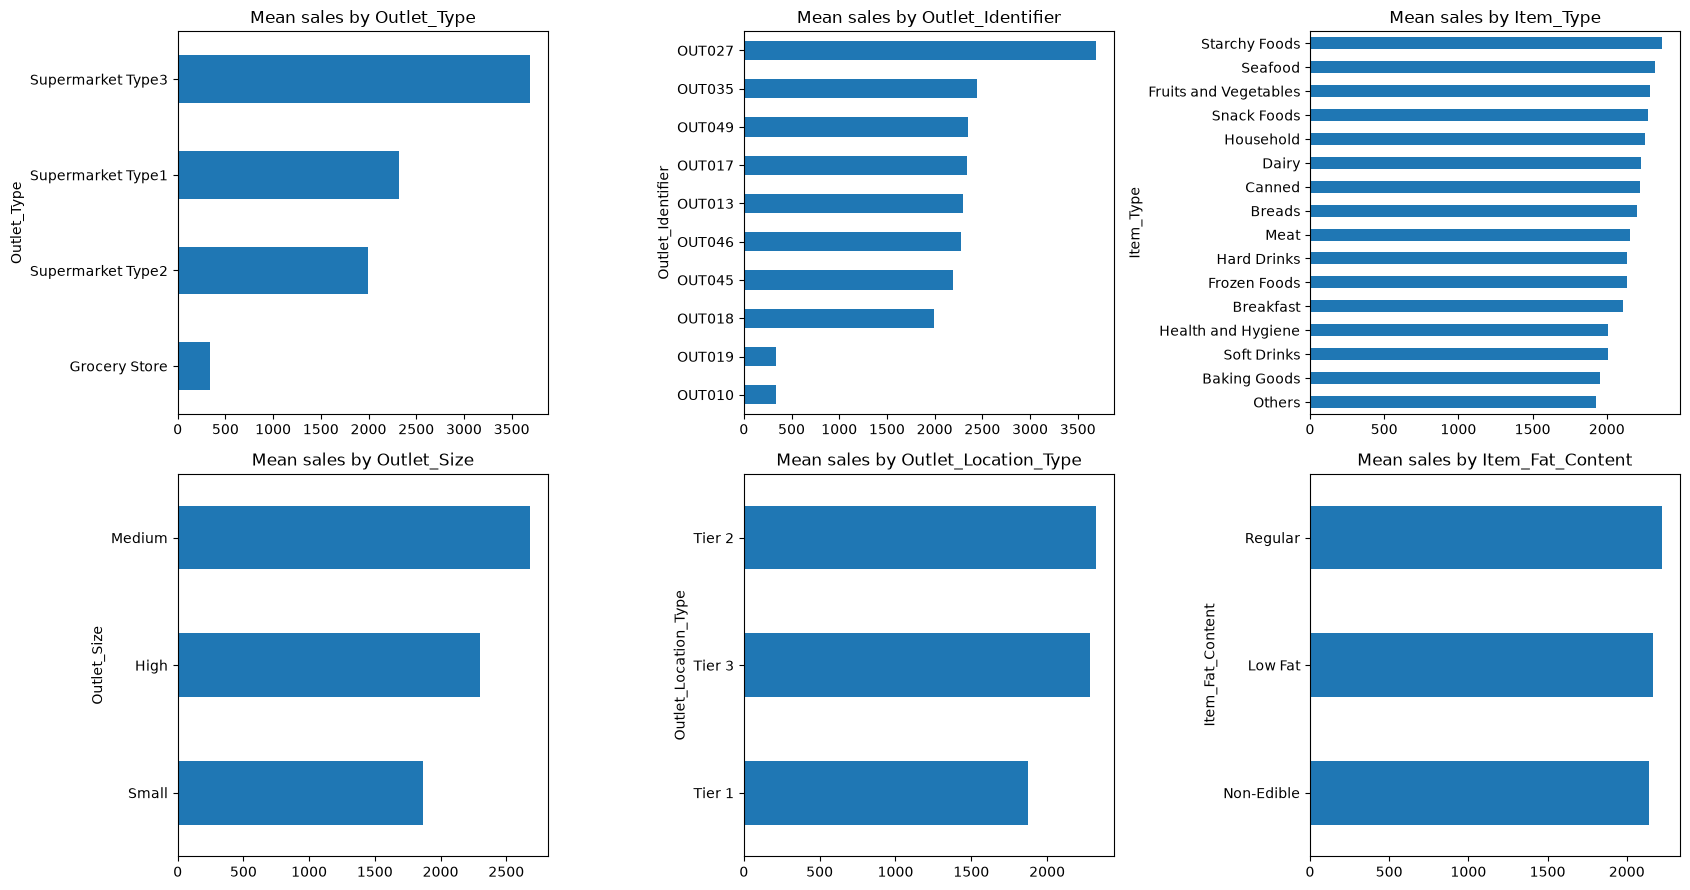

In [8]:
fig, ax = plt.subplots(2, 3, figsize=(17, 9))
for a, col in zip(ax.ravel(), ["Outlet_Type", "Outlet_Identifier", "Item_Type", "Outlet_Size", "Outlet_Location_Type", "Item_Fat_Content"]):
    tr.groupby(col)[TARGET].mean().sort_values().plot.barh(ax=a); a.set_title(f"Mean sales by {col}")
plt.tight_layout(); plt.show()

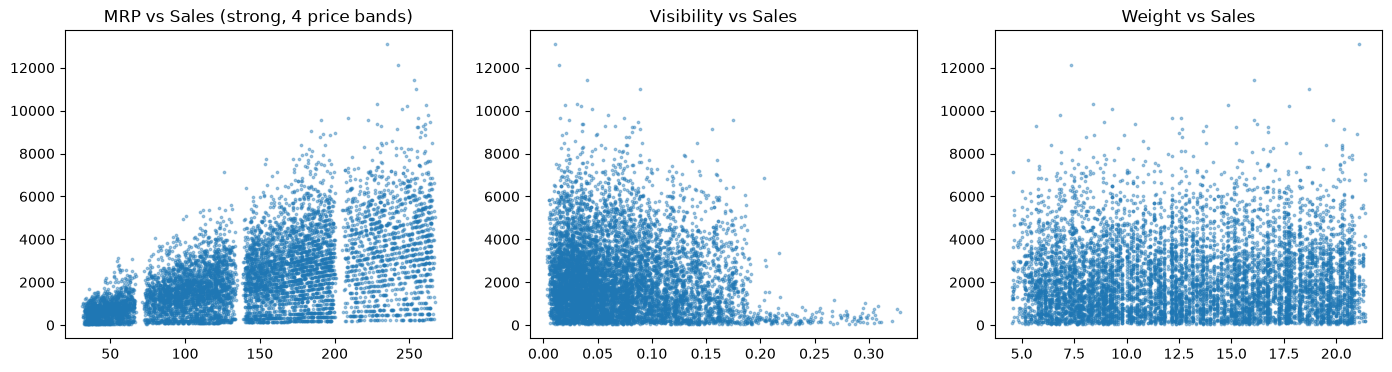

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].scatter(tr["Item_MRP"], tr[TARGET], s=3, alpha=.4); ax[0].set_title("MRP vs Sales (strong, 4 price bands)")
ax[1].scatter(tr["Item_Visibility"], tr[TARGET], s=3, alpha=.4); ax[1].set_title("Visibility vs Sales")
ax[2].scatter(tr["Item_Weight"], tr[TARGET], s=3, alpha=.4); ax[2].set_title("Weight vs Sales")
plt.show()

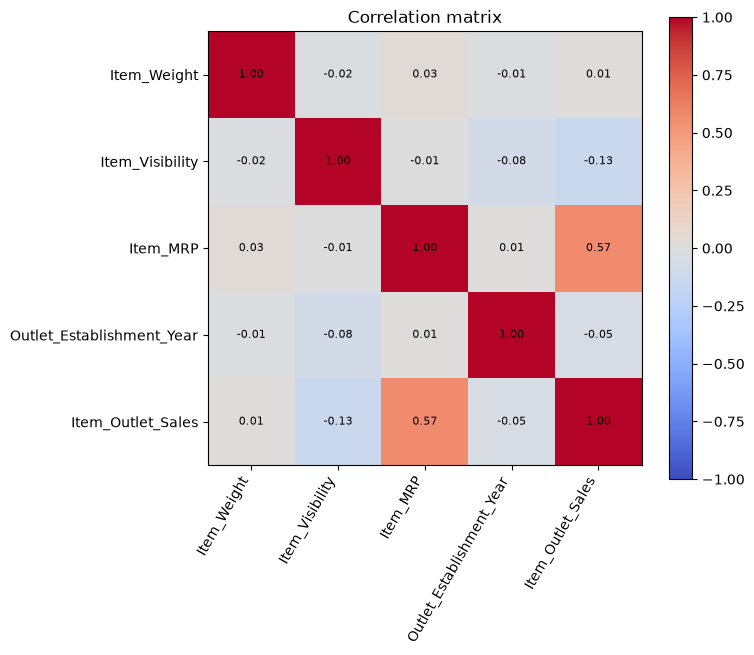

In [10]:
num = tr.select_dtypes("number").drop(columns="is_train")
corr = num.corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im); ax.set_title("Correlation matrix"); plt.show()

**Findings:** sales are right-skewed (so the model is trained on `log1p(sales)`); `Item_MRP` is the strongest driver; Grocery Stores (OUT010, OUT019) sell far less than Supermarkets, and OUT027 (Supermarket Type3) sells the most.

## 4. Feature engineering

In [11]:
full["Outlet_Years"] = 2013 - full["Outlet_Establishment_Year"]
full["Visibility_Ratio"] = full["Item_Visibility"] / full.groupby("Item_Identifier")["Item_Visibility"].transform("mean")
full["MRP_per_Weight"] = full["Item_MRP"] / full["Item_Weight"]
full["MRP_Bin"] = pd.cut(full["Item_MRP"], [0, 69, 136, 203, 400], labels=["Low", "Medium", "High", "Very High"])
full["Item_Count"] = full.groupby("Item_Identifier")["Item_Identifier"].transform("count")
full["MRP_Mean_Item"] = full.groupby("Item_Identifier")["Item_MRP"].transform("mean")
full["MRP_Mean_Outlet"] = full.groupby("Outlet_Identifier")["Item_MRP"].transform("mean")

cat_cols = ["Item_Fat_Content", "Item_Type", "Item_Category", "Outlet_Identifier", "Outlet_Size",
            "Outlet_Location_Type", "Outlet_Type", "MRP_Bin"]
for c in cat_cols:
    full[c] = full[c].astype("category").cat.codes

drop = ["Item_Identifier", TARGET, "is_train", "Outlet_Establishment_Year"]
features = [c for c in full.columns if c not in drop]
cat_mask = [c in cat_cols for c in features]
print(len(features), "features:", features)

X = full.loc[full.is_train == 1, features].reset_index(drop=True)
y_raw = full.loc[full.is_train == 1, TARGET].reset_index(drop=True)
y = np.log1p(y_raw)
X_test = full.loc[full.is_train == 0, features]

17 features: ['Item_Weight', 'Item_Fat_Content', 'Item_Visibility', 'Item_Type', 'Item_MRP', 'Outlet_Identifier', 'Outlet_Size', 'Outlet_Location_Type', 'Outlet_Type', 'Item_Category', 'Outlet_Years', 'Visibility_Ratio', 'MRP_per_Weight', 'MRP_Bin', 'Item_Count', 'MRP_Mean_Item', 'MRP_Mean_Outlet']


## 5. Modelling
80/20 hold-out split for validation.

In [12]:
X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, random_state=42)


def make_model(seed=0):
    return HistGradientBoostingRegressor(learning_rate=0.03, max_iter=400, max_depth=4, min_samples_leaf=40,
                                         l2_regularization=1.0, categorical_features=cat_mask, random_state=seed)


model = make_model().fit(X_tr, y_tr)
pred_val = np.expm1(model.predict(X_val))
true_val = np.expm1(y_val)

## 6. Evaluation

Hold-out RMSE: 1047.55   R2: 0.596
5-fold CV RMSE: 1115.46


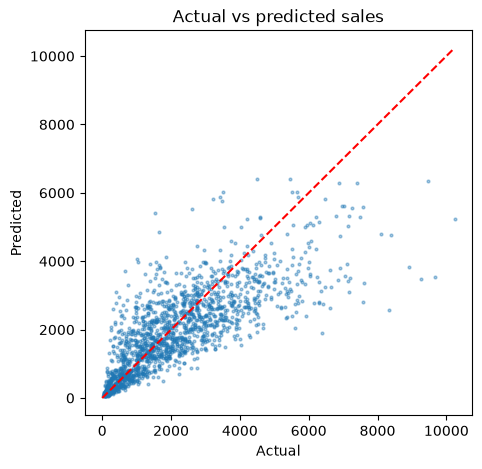

In [13]:
rmse = np.sqrt(mean_squared_error(true_val, pred_val))
print(f"Hold-out RMSE: {rmse:.2f}   R2: {r2_score(true_val, pred_val):.3f}")
oof = np.expm1(cross_val_predict(make_model(), X, y, cv=KFold(5, shuffle=True, random_state=42)))
print(f"5-fold CV RMSE: {np.sqrt(mean_squared_error(y_raw, oof)):.2f}")

plt.figure(figsize=(5, 5)); plt.scatter(true_val, pred_val, s=4, alpha=.4)
lim = [0, max(true_val.max(), pred_val.max())]; plt.plot(lim, lim, "r--")
plt.xlabel("Actual"); plt.ylabel("Predicted"); plt.title("Actual vs predicted sales"); plt.show()

### Confusion matrix, precision, recall, F1
Sales are binned into Low / Medium / High using the tertile cut-offs of the **training** sales.

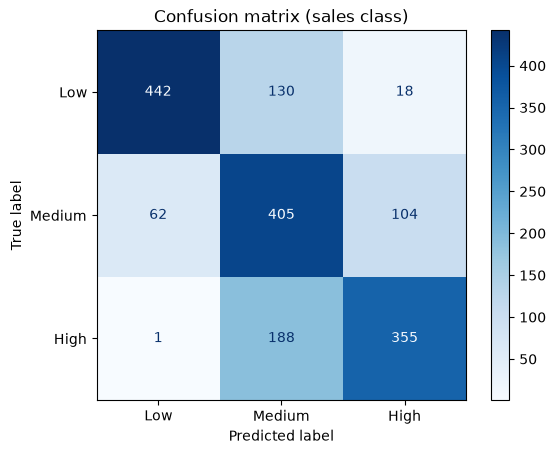

              precision    recall  f1-score   support

         Low      0.875     0.749     0.807       590
      Medium      0.560     0.709     0.626       571
        High      0.744     0.653     0.695       544

    accuracy                          0.705      1705
   macro avg      0.727     0.704     0.710      1705
weighted avg      0.728     0.705     0.711      1705

Accuracy 0.705 | Macro precision 0.727 | recall 0.704 | F1 0.710


In [14]:
q1, q2 = np.quantile(y_raw, [1/3, 2/3])
labels = ["Low", "Medium", "High"]
to_cls = lambda s: pd.cut(s, [-np.inf, q1, q2, np.inf], labels=labels)
y_true_c, y_pred_c = to_cls(true_val), to_cls(pred_val)

cm = confusion_matrix(y_true_c, y_pred_c, labels=labels)
ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap="Blues"); plt.title("Confusion matrix (sales class)"); plt.show()

print(classification_report(y_true_c, y_pred_c, labels=labels, digits=3))
p, r, f, _ = precision_recall_fscore_support(y_true_c, y_pred_c, average="macro")
print(f"Accuracy {accuracy_score(y_true_c, y_pred_c):.3f} | Macro precision {p:.3f} | recall {r:.3f} | F1 {f:.3f}")

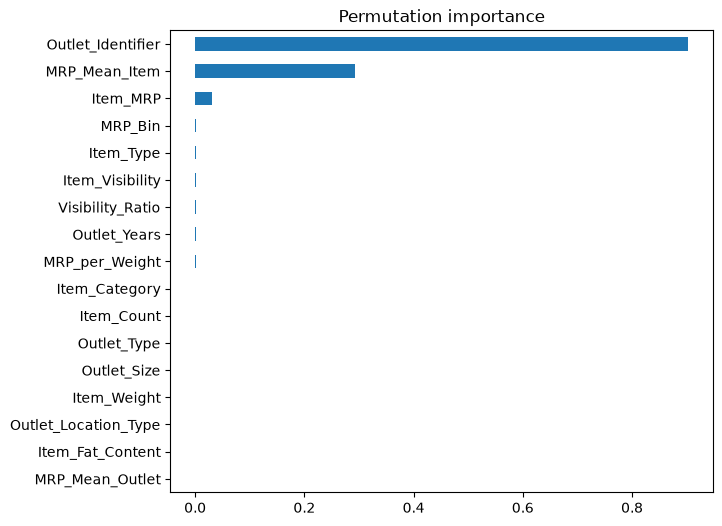

In [15]:
from sklearn.inspection import permutation_importance
imp = permutation_importance(model, X_val, y_val, n_repeats=5, random_state=0)
pd.Series(imp.importances_mean, index=features).sort_values().plot.barh(figsize=(7, 6), title="Permutation importance")
plt.show()

## 7. Final model & submission
Retrain on all training data (averaging 5 seeds) and write `submission.csv`.

In [16]:
preds = np.mean([np.expm1(make_model(s).fit(X, y).predict(X_test)) for s in range(5)], axis=0)
sub = test[["Item_Identifier", "Outlet_Identifier"]].copy()
sub[TARGET] = np.clip(preds, 0, None)
sub.to_csv("submission.csv", index=False)
print(sub.shape); sub.head()

(5681, 3)


,Item_Identifier,Outlet_Identifier,Item_Outlet_Sales
0,FDW58,OUT049,1440.941293
1,FDW14,OUT017,1232.104290
2,NCN55,OUT010,499.976024
3,FDQ58,OUT017,2255.060333
4,FDY38,OUT027,5426.149467
